#Imports

In [49]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans

#Carregando arquivo

In [15]:
df = pd.read_csv("/content/titanic_dashboard (1).csv")
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Survived    891 non-null    int64  
 1   Pclass      891 non-null    int64  
 2   Age         891 non-null    int64  
 3   Fare        891 non-null    float64
 4   Sex_female  891 non-null    int64  
 5   Sex_male    891 non-null    int64  
 6   Embarked_C  891 non-null    int64  
 7   Embarked_Q  891 non-null    int64  
 8   Embarked_S  891 non-null    int64  
 9   IsAlone     891 non-null    int64  
 10  AgeGroup    884 non-null    object 
dtypes: float64(1), int64(9), object(1)
memory usage: 76.7+ KB


#Logistic Regression

💡 **Insight: Limiares e Probabilidades**
O modelo gera uma probabilidade (ex: 0.8 -> provavelmente sobrevive). O limiar padrão é 0.50.
Você pode brincar com esse limite para melhorar o *Recall* (pegar mais sobreviventes) ou *Precision* (evitar erros de falso positivo).

In [16]:
df_copy_lr = df.copy()

# Evitar redundâncias
df_copy_lr = df_copy_lr.drop(columns=['Sex_male'])
df_copy_lr = df_copy_lr.drop(columns=['Embarked_S'])

# One-Hot Encoding
df_copy_lr = pd.get_dummies(df_copy_lr, columns=['AgeGroup'], drop_first=True)

df_copy_lr.head()

,Survived,Pclass,Age,Fare,Sex_female,Embarked_C,Embarked_Q,IsAlone,AgeGroup_Adulto,AgeGroup_Criança,AgeGroup_Idoso,AgeGroup_Meia-idade
0,0,3,22,7.2500,0,0,0,0,True,False,False,False
1,1,1,38,71.2833,1,1,0,0,True,False,False,False
2,1,3,26,7.9250,1,0,0,1,True,False,False,False
3,1,1,35,53.1000,1,0,0,0,True,False,False,False
4,0,3,35,8.0500,0,0,0,1,True,False,False,False


In [17]:
X = df_copy_lr.drop(columns=['Survived'])
y = df_copy_lr['Survived']

In [18]:
# Separação de treino + validação e teste
# Treino + validação (80%)
# Teste (20%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Separação de treino e validação
# Treino (60%)
# Validação (20%)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42
)

In [19]:
# Normalizando dados para o modelo
scaler = StandardScaler()

# Aprende com treino
X_train[['Age', 'Fare']] = scaler.fit_transform(X_train[['Age', 'Fare']])

# Aplica nos outros
X_val[['Age', 'Fare']] = scaler.transform(X_val[['Age', 'Fare']])
X_test[['Age', 'Fare']] = scaler.transform(X_test[['Age', 'Fare']])

In [20]:
model = LogisticRegression(
    max_iter=1000,
    C=1.0,
    penalty='l2',
    solver='lbfgs'
)

In [21]:
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [22]:
from sklearn.metrics import accuracy_score, classification_report

y_val_pred = model.predict(X_val)

print("Accuracy (validação):", accuracy_score(y_val, y_val_pred))
print(classification_report(y_val, y_val_pred))

Accuracy (validação): 0.797752808988764
              precision    recall  f1-score   support

           0       0.84      0.84      0.84       112
           1       0.73      0.73      0.73        66

    accuracy                           0.80       178
   macro avg       0.78      0.78      0.78       178
weighted avg       0.80      0.80      0.80       178



In [23]:
coef = pd.Series(model.coef_[0], index=X.columns)
print(coef.sort_values(ascending=False))

Sex_female             2.387706
Embarked_C             0.622378
Embarked_Q             0.529796
AgeGroup_Criança       0.376094
AgeGroup_Idoso         0.107993
Fare                   0.040646
IsAlone               -0.018758
AgeGroup_Adulto       -0.066612
AgeGroup_Meia-idade   -0.137447
Age                   -0.214881
Pclass                -1.056211
dtype: float64


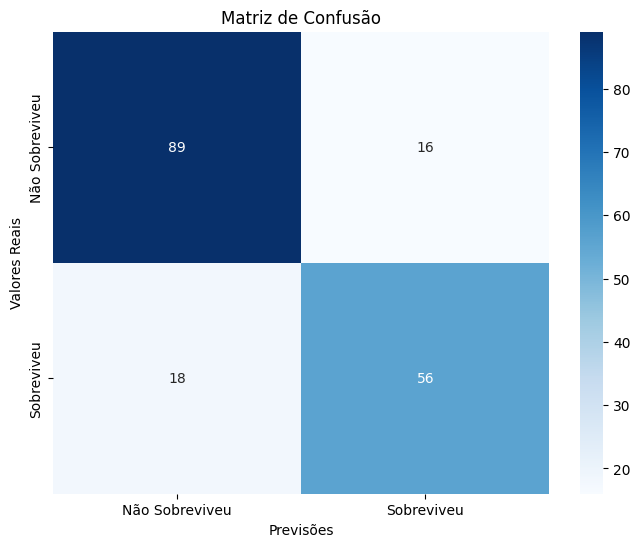


Métricas de Desempenho no Conjunto de Teste:

              precision    recall  f1-score   support

           0       0.83      0.85      0.84       105
           1       0.78      0.76      0.77        74

    accuracy                           0.81       179
   macro avg       0.80      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179



In [24]:
y_test_pred = model.predict(X_test)
# Gerar a matriz de confusão
cm = confusion_matrix(y_test, y_test_pred)

# Plotar a matriz de confusão
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Não Sobreviveu', 'Sobreviveu'],
            yticklabels=['Não Sobreviveu', 'Sobreviveu'])
plt.xlabel('Previsões')
plt.ylabel('Valores Reais')
plt.title('Matriz de Confusão')
plt.show()

# Tabela com Recall, Precision, F1-score e Acurácia
print("\nMétricas de Desempenho no Conjunto de Teste:\n")
print(classification_report(y_test, y_test_pred))

#Linear Regression

⚠️ **Nota sobre Regressão Linear no Titanic**
A regressão linear tenta desenhar uma linha que melhor representa os dados. Funciona bem para aprender o básico, mas **o Titanic NÃO é muito linear**.
Portanto, não é o melhor modelo na prática para esse dataset.

In [25]:
df_copy_lnr = df.copy()

# Evitar redundâncias
df_copy_lnr = df_copy_lnr.drop(columns=['Sex_male'])
df_copy_lnr = df_copy_lnr.drop(columns=['Embarked_S'])

# One-Hot Encoding
df_copy_lnr = pd.get_dummies(df_copy_lnr, columns=['AgeGroup'], drop_first=True)

df_copy_lnr.head()

,Survived,Pclass,Age,Fare,Sex_female,...,IsAlone,AgeGroup_Adulto,AgeGroup_Criança,AgeGroup_Idoso,AgeGroup_Meia-idade
0,0,3,22,7.2500,0,...,0,True,False,False,False
1,1,1,38,71.2833,1,...,0,True,False,False,False
2,1,3,26,7.9250,1,...,1,True,False,False,False
3,1,1,35,53.1000,1,...,0,True,False,False,False
4,0,3,35,8.0500,0,...,1,True,False,False,False


In [26]:
X = df_copy_lnr.drop(columns=['Survived'])
y = df_copy_lnr['Survived']

In [27]:
# Separação de treino + validação e teste
# Treino + validação (80%)
# Teste (20%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Separação de treino e validação
# Treino (60%)
# Validação (20%)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42
)

In [28]:
# Normalizando dados para o modelo
scaler = StandardScaler()

# Aprende com treino
X_train[['Age', 'Fare']] = scaler.fit_transform(X_train[['Age', 'Fare']])

# Aplica nos outros
X_val[['Age', 'Fare']] = scaler.transform(X_val[['Age', 'Fare']])
X_test[['Age', 'Fare']] = scaler.transform(X_test[['Age', 'Fare']])

In [29]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [30]:
y_val_pred = model.predict(X_val)

In [31]:
# 5. Predição e Avaliação no Conjunto de Validação
y_val_pred = model.predict(X_val)

mse_val = mean_squared_error(y_val, y_val_pred)
r2_val = r2_score(y_val, y_val_pred)
print("--- AVALIAÇÃO NO CONJUNTO DE VALIDAÇÃO ---")
print(f"Mean Squared Error (MSE): {mse_val:.4f}")
print(f"R² Score: {r2_val:.4f}\n")
print("--- COEFICIENTES DO MODELO ---")
print(f"Intercepto (b): {model.intercept_:.4f}")
for col, coef in zip(X_train.columns, model.coef_):
    print(f"Peso de '{col}': {coef:.4f}")

--- AVALIAÇÃO NO CONJUNTO DE VALIDAÇÃO ---
Mean Squared Error (MSE): 0.1463
R² Score: 0.3727

--- COEFICIENTES DO MODELO ---
Intercepto (b): 0.5936
Peso de 'Pclass': -0.1792
Peso de 'Age': -0.0303
Peso de 'Fare': 0.0071
Peso de 'Sex_female': 0.4834
Peso de 'Embarked_C': 0.1121
Peso de 'Embarked_Q': 0.0939
Peso de 'IsAlone': 0.0070
Peso de 'AgeGroup_Adulto': -0.0013
Peso de 'AgeGroup_Criança': 0.0979
Peso de 'AgeGroup_Idoso': 0.0247
Peso de 'AgeGroup_Meia-idade': -0.0231



--- TABELA DE COEFICIENTES DO MODELO ---
           Variável  Peso (Coeficiente)
     Intercepto (b)            0.593640
             Pclass           -0.179220
                Age           -0.030277
               Fare            0.007059
         Sex_female            0.483407
         Embarked_C            0.112052
         Embarked_Q            0.093927
            IsAlone            0.007027
    AgeGroup_Adulto           -0.001335
   AgeGroup_Criança            0.097878
     AgeGroup_Idoso            0.024705
AgeGroup_Meia-idade           -0.023108


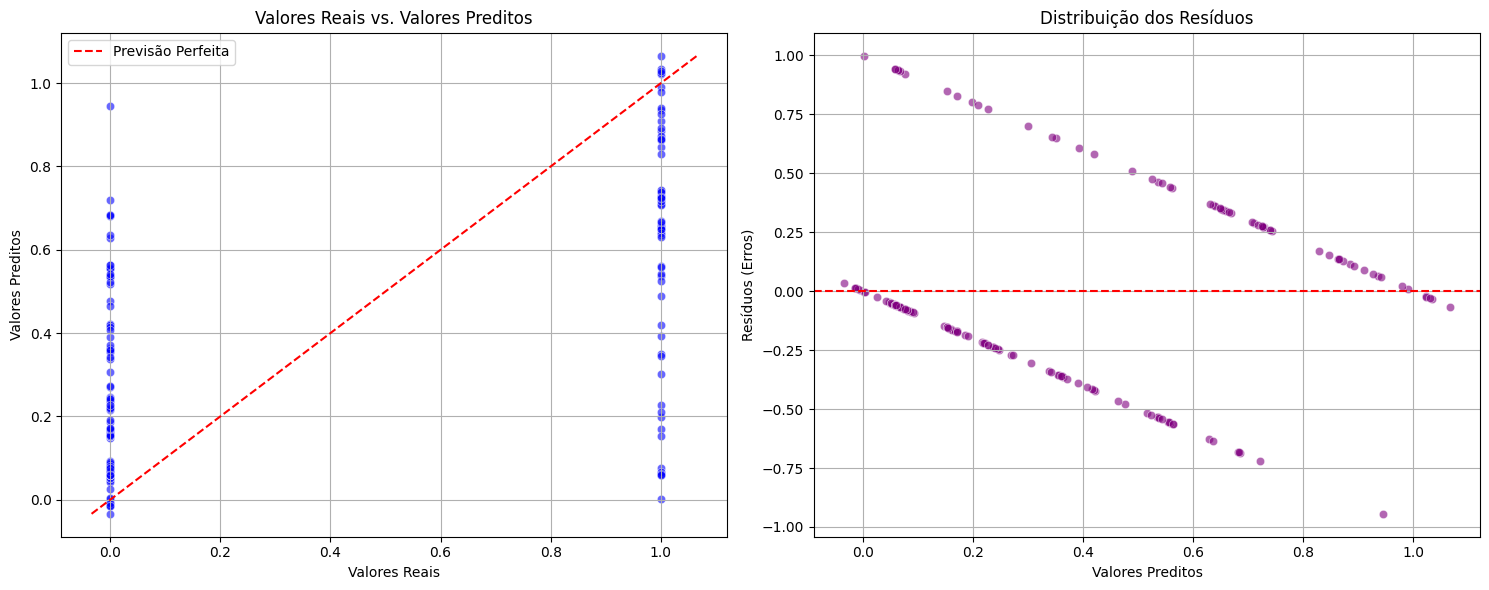

In [32]:
# ==========================================
# 1. TABELA DE COEFICIENTES E IMPORTÂNCIA
# ==========================================
df_coeficientes = pd.DataFrame({
    'Variável': X_train.columns,
    'Peso (Coeficiente)': model.coef_
})

# Adiciona o Intercepto na tabela para ficar completo
df_coeficientes = pd.concat([
    pd.DataFrame({'Variável': ['Intercepto (b)'], 'Peso (Coeficiente)': [model.intercept_]}),
    df_coeficientes
]).reset_index(drop=True)

print("\n--- TABELA DE COEFICIENTES DO MODELO ---")
print(df_coeficientes.to_string(index=False))


# ==========================================
# 2. GRÁFICOS DE DIAGNÓSTICO
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Gráfico 1: Real vs. Predito
sns.scatterplot(ax=axes[0], x=y_val, y=y_val_pred, alpha=0.6, color='b')
# Linha de referência para uma previsão perfeita
limites = [min(y_val.min(), y_val_pred.min()), max(y_val.max(), y_val_pred.max())]
axes[0].plot(limites, limites, color='red', linestyle='--', label='Previsão Perfeita')
axes[0].set_xlabel('Valores Reais')
axes[0].set_ylabel('Valores Preditos')
axes[0].set_title('Valores Reais vs. Valores Preditos')
axes[0].legend()
axes[0].grid(True)

# Gráfico 2: Análise de Resíduos (Erros)
residuos = y_val - y_val_pred
sns.scatterplot(ax=axes[1], x=y_val_pred, y=residuos, alpha=0.6, color='purple')
axes[1].axhline(y=0, color='red', linestyle='--')
axes[1].set_xlabel('Valores Preditos')
axes[1].set_ylabel('Resíduos (Erros)')
axes[1].set_title('Distribuição dos Resíduos')
axes[1].grid(True)

plt.tight_layout()
plt.show()

#Isolation Forest

🔥 **Destaque: Detecção de Outliers**
O modelo 'isola' pontos estranhos (ex: tarifas absurdamente altas ou idades anômalas).
Funciona muito bem sem muito ajuste e é um excelente diferencial automático em pipelines de dados.

In [37]:
df_copy_if = df.copy()
X_outliers = df_copy_if.drop(columns=['Survived'], errors='ignore')

In [38]:
X_outliers = pd.get_dummies(X_outliers, drop_first=True)

In [46]:
iso_forest = IsolationForest(
    contamination=0.05,
    n_estimators=150,     # Número de árvores (aumentado para 150 para maior estabilidade)
    bootstrap=True,       # Amostragem com reposição
    random_state=42
)

In [47]:
# Ajustamos o modelo e geramos as predições de uma vez:
# Retorna 1 para dados NORMAIS e -1 para OUTLIERS

df_copy_if['outlier'] = iso_forest.fit_predict(X_outliers)

--- CONTAGEM DE OUTLIERS ---
outlier
Normal (1)      846
Outlier (-1)     45
Name: count, dtype: int64


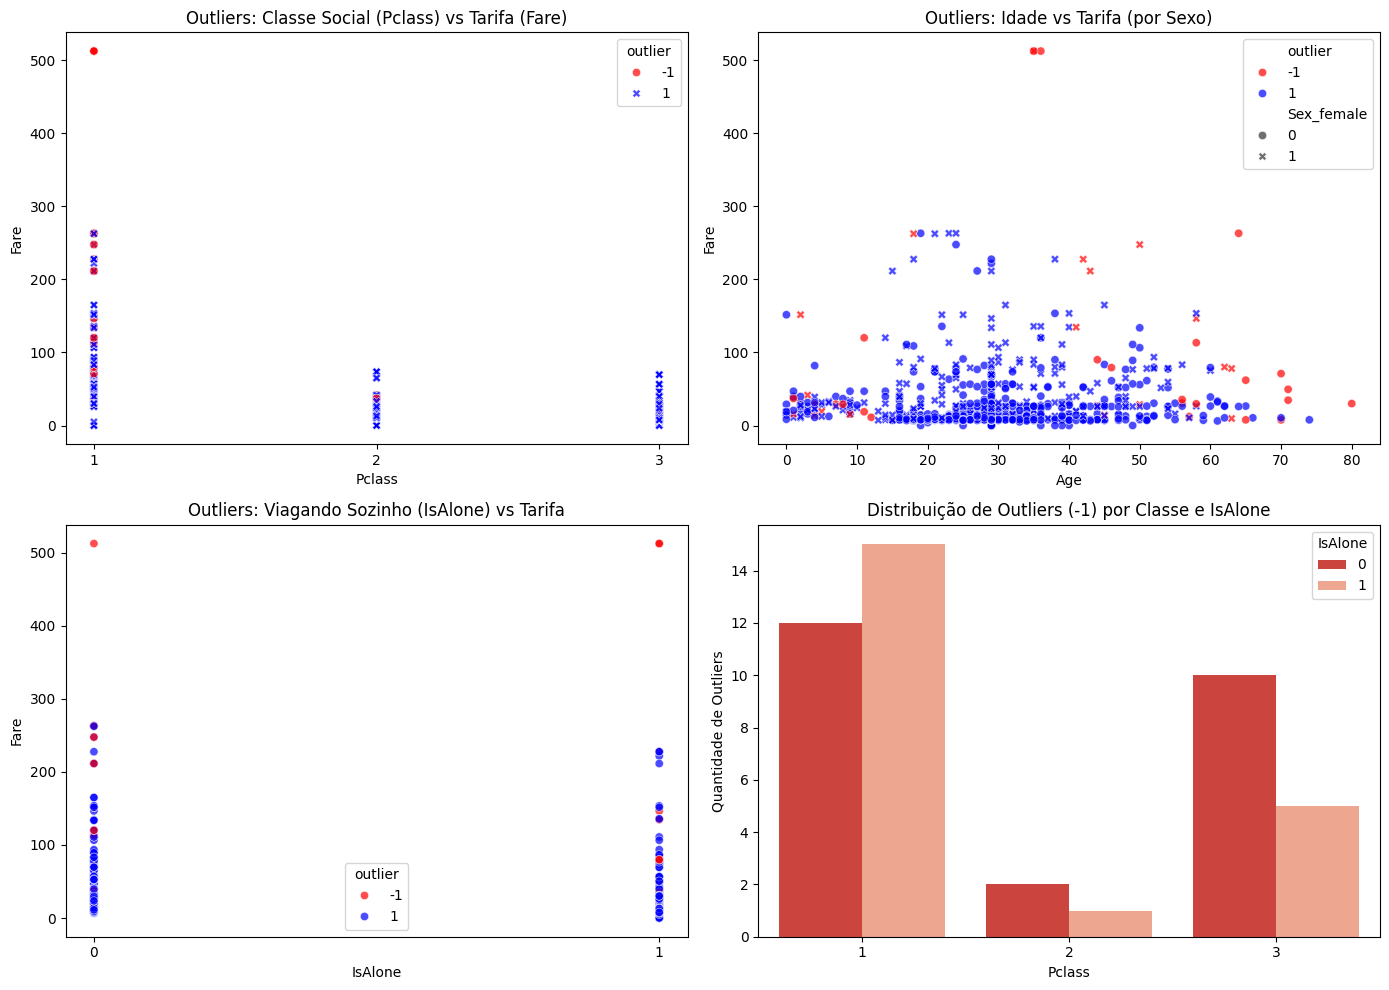

In [48]:
# 3. Relatório em Tabela
print("--- CONTAGEM DE OUTLIERS ---")
contagem = df_copy_if['outlier'].value_counts().rename(index={1: 'Normal (1)', -1: 'Outlier (-1)'})
print(contagem)


# 4. Visualização Gráfica em Painel para as Principais Variáveis
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Gráfico 1: Pclass vs Fare (Muitos outliers costumam ser passagens caríssimas na 1ª classe)
sns.scatterplot(
    ax=axes[0, 0], data=df_copy_if, x='Pclass', y='Fare', hue='outlier',
    palette={1: 'blue', -1: 'red'}, alpha=0.7, style='outlier'
)
axes[0, 0].set_title('Outliers: Classe Social (Pclass) vs Tarifa (Fare)')
axes[0, 0].set_xticks([1, 2, 3])

# Gráfico 2: Age vs Fare por Sexo (Sex_female: 1 = Mulher, 0 = Homem)
sns.scatterplot(
    ax=axes[0, 1], data=df_copy_if, x='Age', y='Fare', hue='outlier', style='Sex_female',
    palette={1: 'blue', -1: 'red'}, alpha=0.7
)
axes[0, 1].set_title('Outliers: Idade vs Tarifa (por Sexo)')

# Gráfico 3: IsAlone vs Fare
sns.scatterplot(
    ax=axes[1, 0], data=df_copy_if, x='IsAlone', y='Fare', hue='outlier',
    palette={1: 'blue', -1: 'red'}, alpha=0.7
)
axes[1, 0].set_title('Outliers: Viagando Sozinho (IsAlone) vs Tarifa')
axes[1, 0].set_xticks([0, 1])

# Gráfico 4: Proporção de Outliers por Pclass e IsAlone (Contagem)
sns.countplot(
    ax=axes[1, 1], data=df_copy_if[df_copy_if['outlier'] == -1], x='Pclass', hue='IsAlone',
    palette='Reds_r'
)
axes[1, 1].set_title('Distribuição de Outliers (-1) por Classe e IsAlone')
axes[1, 1].set_ylabel('Quantidade de Outliers')

plt.tight_layout()
plt.show()

#K-Means

👥 **Insight: Agrupamento**
K-Means agrupa pessoas parecidas (ex: ricos, famílias grandes).
É crucial notar que este modelo precisa de **dados normalizados** e de uma boa escolha para o número de clusters (K).

In [51]:
X_kmeans = df.drop(columns=['Survived'], errors='ignore')
X_kmeans = pd.get_dummies(X_kmeans, columns=['AgeGroup'], drop_first=True, dummy_na=False)
X_kmeans = X_kmeans.fillna(X_kmeans.median())

In [52]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_kmeans)

In [64]:
# 3. Método do Cotovelo (Elbow Method) para encontrar o 'K' Ideal
inercias = []
k_range = range(1, 10)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inercias.append(kmeans.inertia_)

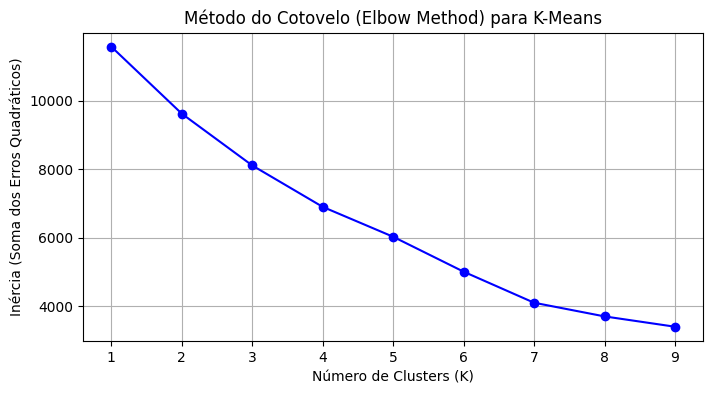

In [63]:
# Plot do Método do Cotovelo
plt.figure(figsize=(8, 4))
plt.plot(k_range, inercias, 'bo-')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Inércia (Soma dos Erros Quadráticos)')
plt.title('Método do Cotovelo (Elbow Method) para K-Means')
plt.grid(True)
plt.show()

--- PERFIL MÉDIO DE CADA CLUSTER (K=3) ---
         Pclass    Age   Fare  IsAlone  Sex_female
cluster                                           
0          1.74  51.20  42.62     0.59        0.32
1          2.24  24.32  45.10     0.41        0.99
2          2.52  25.74  21.68     0.71        0.00


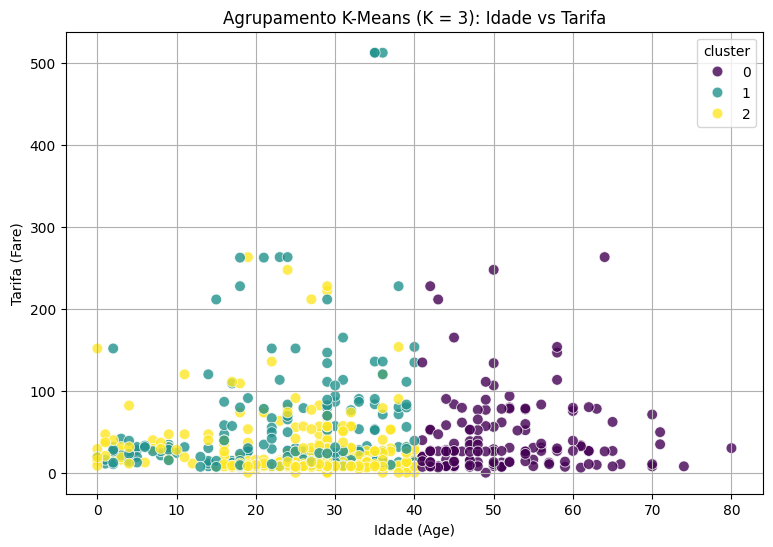

In [62]:
# 1. Instanciando e Treinando o K-Means com K=3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Ajusta com os dados padronizados e gera os rótulos dos clusters (0, 1 e 2)
X_kmeans['cluster'] = kmeans.fit_predict(X_scaled)

# 2. Análise do Perfil dos Grupos (Média das variáveis por Cluster)
# Mostra o comportamento de cada grupo no dataset original
colunas_analise = ['Pclass', 'Age', 'Fare', 'IsAlone', 'Sex_female']
perfil_clusters = X_kmeans.groupby('cluster')[colunas_analise].mean()

print("--- PERFIL MÉDIO DE CADA CLUSTER (K=3) ---")
print(perfil_clusters.round(2))

# 3. Visualização Gráfica dos Clusters (Ex: Idade vs Tarifa)
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=X_kmeans,
    x='Age',
    y='Fare',
    hue='cluster',
    palette='viridis',
    alpha=0.8,
    s=60
)
plt.title('Agrupamento K-Means (K = 3): Idade vs Tarifa')
plt.xlabel('Idade (Age)')
plt.ylabel('Tarifa (Fare)')
plt.grid(True)
plt.show()